<div style="display: flex; justify-content: space-between; align-items: flex-start; border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: -8px;">
    <div style="width: 50%;">
        <h2><span style="color: #B30033;">▍</span>TRABAJO DE FIN DE MÁSTER</h2>
        <h1 style="margin-top: -10px;">MARCO DE TRABAJO DE RECOMENDACIÓN DE PERSONAL PARA LA FORMACIÓN DE EQUIPOS EN PROYECTOS DE INGENIERÍA DEL SOFTWARE</h1>
    </div>
    <div style="width: 50%; text-align: right;">
        <div style="display: flex; justify-content: space-between; align-items: flex-start; margin-top: 30px;">
            <div style="width: 20%;"></div>
            <div style="width: 80%; border-left: 2px solid #555555; padding-left: 20px;">
                <div style="margin-bottom: 20px;"><p style="margin: 0; font-size: 1.4em; font-weight: bold;">TUTORES</p></div>
                <div style="margin-top: 8px; text-align: right;">
                    <span style="display: block; font-size: 1em; color: #D0D0D0;">Aurora Vizcaíno Barcelo</span>
                    <span style="display: block; font-size: 1em; color: #D0D0D0; margin-top: 5px;">Julio Alberto López Gómez</span>
                </div>
            </div>
        </div>
    </div>
</div>

<div style="margin-top: 30px; padding: 20px; background-color: rgba(179, 0, 51, 0.05); border-left: 4px solid #B30033; border-radius: 4px;">
    <h3 style="margin-top: 0; color: #B30033;">🎯 Objetivo de esta Libreta (Fase 3: Minería de Reglas de Asociación — Hard Skills)</h3>
    <p style="font-size: 1.1em; line-height: 1.6; color: #E0E0E0;">
        En esta tercera fase partimos de la matriz transaccional binaria obtenida en la segunda libreta de Feature Engineering (35.434 candidatos y 263 columnas). El objetivo es replicar la metodología ya aplicada en el pipeline de soft skills, esta vez sobre las habilidades técnicas: extraer reglas con Apriori, FP-Growth y Eclat, filtrar las reglas que no aportan valor y comparar cuál de los tres algoritmos presenta un mejor rendimiento en cuanto a resultados y tiempos.
    </p>
    <ul style="font-size: 1.1em; line-height: 1.6; color: #D0D0D0; margin-bottom: 0;">
        <li><strong>Diferencias respecto a soft skills:</strong> en este pipeline no existen proxies de personalidad, por lo que el filtrado de circularidad no puede basarse en ellos. En su lugar, se aplica un criterio de redundancia basado en la correlación entre variables numéricas identificada en el EDA (<code>WorkExp</code> y <code>YearsCode</code>).</li>
        <li><strong>Calibración de parámetros:</strong> la elección de <code>min_support</code> ya resultó delicada en el pipeline de soft skills, y aquí debe recalibrarse, ya que la matriz tiene una mayor dimensionalidad (263 columnas frente a 205) aunque menos candidatos.</li>
    </ul>
</div>

<div style="border-bottom: 2px solid #555555; padding-bottom: 25px; margin-bottom: 10px">
    <div style="display: flex; align-items: center; margin-bottom: 10px;">
        <span style="color: #B30033; font-size: 1.5em; margin-right: 10px;">▍</span>
        <h3 style="margin: 0; font-size: 1.4em; font-weight: bold">
            Realizado por Miguel Ángel Sánchez-Medina Camacho <span style="font-size: 0.7em; font-style: italic; font-weight: normal;"></span>
        </h3>
    </div>
</div>

### 3.1 Configuración del entorno y carga de la matriz transaccional

Primero, como siempre, importamos las librerías necesarias para esta libreta:

* `mlxtend`, de la que importamos `apriori` y `fpgrowth` para la extracción de itemsets frecuentes y `association_rules` para la generación de reglas, de la misma forma que en el pipeline de soft skills.
* El módulo `utils`, que incluye las funciones auxiliares `barrido_min_support` y `probar_eclat`; esta última utiliza internamente la librería `pyECLAT` para ejecutar el tercer algoritmo.

Después, cargamos la matriz generada en la libreta anterior (**35.434 candidatos y 263 columnas**) y la convertimos a tipo booleano (`True`/`False`), ya que es el formato con el que `mlxtend` la procesa de forma más eficiente.

In [1]:
import os
import sys
import time
sys.path.append(os.path.abspath(os.path.join('../..')))

from src.hard_skills import config, utils
import pandas as pd
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import matplotlib.pyplot as plt

df_matriz = pd.read_csv(config.MATRIZ_TRANSACCIONAL_PATH, index_col='CandidateId')
df_matriz = df_matriz.fillna(0).astype(bool)

print(f"Dimensiones matriz: {df_matriz.shape}")
display(df_matriz.head(3))

Dimensiones matriz: (35434, 263)


,WorkExp_is_missing,YearsCode_is_missing,ToolCountWork_is_missing,JobSat_is_missing,ConvertedCompYearly_is_missing,EdLevel_is_missing,RemoteWork_is_missing,OrgSize_is_missing,Industry_is_missing,LanguageHaveWorkedWith_JavaScript,...,ToolCountWork_Bin_<=4,ToolCountWork_Bin_>20,ConvertedCompYearly_Bin_100-150k,ConvertedCompYearly_Bin_40-70k,ConvertedCompYearly_Bin_70-100k,ConvertedCompYearly_Bin_<40k,ConvertedCompYearly_Bin_>150k,JobSat_Bin_Alta (8-10),JobSat_Bin_Baja (0-5),JobSat_Bin_Media (6-7)
CandidateId,,,,,,,,,,,,,,,,,,,,,
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,True,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,True,False,False
2,False,False,False,False,False,False,True,True,False,True,...,True,False,False,True,False,False,False,True,False,False


### 3.2 Generación de itemsets frecuentes — 1er algoritmo: Apriori

Como ya hicimos en el pipeline de las soft skills, aquí vamos a realizar un proceso equivalente para estos datos. Para ello, primero recordamos algunos conceptos ya vistos y explicamos las decisiones tomadas para esta fase del proyecto.

**Conceptos clave utilizados en esta libreta:**
- **Soporte** (`support`): número de transacciones que contienen el itemset dividido entre el total de transacciones. En nuestro caso, la proporción de candidatos en los que aparece un itemset.
- **Confianza** (`confidence`): probabilidad de que se cumpla el consecuente de una regla una vez que se cumple el antecedente. Es una probabilidad condicional, no simétrica.
- **Lift**: cuánto más frecuente es la combinación de antecedente y consecuente de lo que cabría esperar si fueran independientes. Un lift de 1 indica independencia, por encima de 1 una asociación positiva y por debajo de 1 una asociación negativa.

**Configuración de hiperparámetros:**

- **`max_len=4`:** limitar el tamaño máximo de un itemset a 4 ítems es suficiente para mantener las reglas interpretables en esta primera exploración, ya que una regla que combina 5 o 6 ítems empieza a ser difícil de leer. Además, actúa como control de memoria, al igual que `low_memory=True`.
- **`min_confidence=0.6`:** umbral mínimo de confianza que se aplicará al generar las reglas, el mismo empleado en el pipeline de soft skills.
- **`min_support`:** no está claro a priori qué valor es el más adecuado, por lo que realizamos un barrido con varios valores (0,20, 0,18, 0,15, 0,12, 0,10, 0,08 y 0,05) y comparamos el número de itemsets obtenidos y los tiempos de ejecución para decidir cuál emplear en las fases posteriores.

In [2]:
valores_min_support = [0.20, 0.18, 0.15, 0.12, 0.10, 0.08, 0.05]
df_crecimiento, ms_codo = utils.barrido_min_support(df_matriz, valores_min_support, algoritmo=apriori, low_memory=True)
display(df_crecimiento)
print(f"Mayor salto de complejidad en min_support={ms_codo}")

,min_support,n_itemsets,tiempo_s,delta_itemsets,delta_support,itemsets_por_0.01_bajado
0,0.20,880,2.44,NaN,NaN,NaN
1,0.18,1414,3.58,534.0,0.02,267.000000
2,0.15,3165,6.16,1751.0,0.03,583.666667
3,0.12,7548,10.51,4383.0,0.03,1461.000000
4,0.10,14347,16.01,6799.0,0.02,3399.500000
5,0.08,29704,26.09,15357.0,0.02,7678.500000
6,0.05,114831,68.66,85127.0,0.03,28375.666667


Mayor salto de complejidad en min_support=0.05


Como vemos, a partir de valores iguales o inferiores a 0,10 el número de itemsets crece de forma muy acusada (14.347 con 0,10 y 114.831 con 0,05), y los tiempos de ejecución aumentan en la misma medida, por lo que dejan de ser rentables para nuestros objetivos.

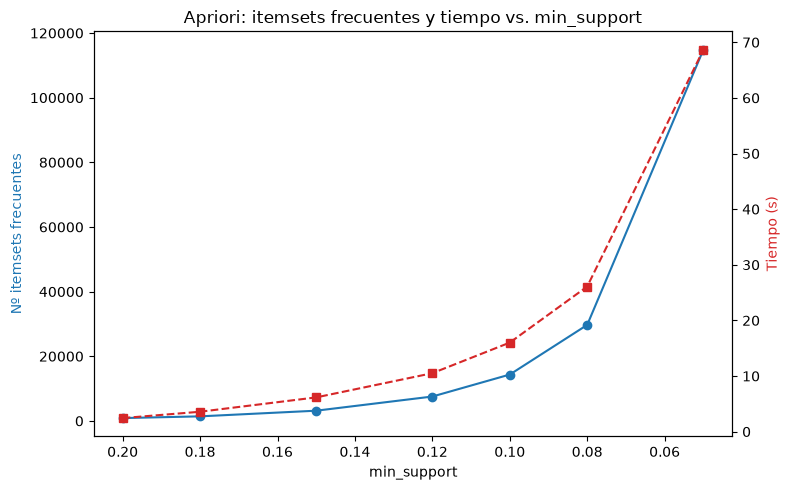

In [3]:
def graficar_barrido(df_sweep, titulo):
    fig, ax1 = plt.subplots(figsize=(8, 5))
    ax1.plot(df_sweep['min_support'], df_sweep['n_itemsets'], marker='o', color='tab:blue')
    ax1.set_xlabel('min_support')
    ax1.set_ylabel('Nº itemsets frecuentes', color='tab:blue')
    ax1.invert_xaxis()
    ax2 = ax1.twinx()
    ax2.plot(df_sweep['min_support'], df_sweep['tiempo_s'], marker='s', color='tab:red', linestyle='--')
    ax2.set_ylabel('Tiempo (s)', color='tab:red')
    plt.title(titulo)
    plt.tight_layout()
    plt.show()

graficar_barrido(df_crecimiento, 'Apriori: itemsets frecuentes y tiempo vs. min_support')

En la gráfica se observa que el rango más adecuado para nuestras necesidades se sitúa entre 0,15 y 0,10: por encima, el número de itemsets es demasiado reducido, y por debajo, los resultados son demasiado numerosos y los tiempos más elevados de lo que requerimos.

Ante esta duda, comparamos los dos extremos de ese rango (0,15 y 0,10) para ver qué supone pasar de uno a otro en número de itemsets y de reglas, y decidir con cuál nos quedamos.

In [4]:
candidatos_min_support = [0.15, 0.10]
resumen_candidatos = []

for ms in candidatos_min_support:
    its = apriori(df_matriz, min_support=ms, use_colnames=True, max_len=4, low_memory=True, verbose=0)
    rgs = association_rules(its, metric="confidence", min_threshold=0.6)
    resumen_candidatos.append({'min_support': ms, 'n_itemsets': len(its), 'n_reglas': len(rgs)})
    del its, rgs

df_resumen_candidatos = pd.DataFrame(resumen_candidatos)
display(df_resumen_candidatos)
print(f"\nAl bajar de 0.15 a 0.10: itemsets x{df_resumen_candidatos.loc[1,'n_itemsets']/df_resumen_candidatos.loc[0,'n_itemsets']:.1f}, "
      f"reglas x{df_resumen_candidatos.loc[1,'n_reglas']/df_resumen_candidatos.loc[0,'n_reglas']:.1f}")

,min_support,n_itemsets,n_reglas
0,0.15,3165,10178
1,0.10,14347,43632



Al bajar de 0.15 a 0.10: itemsets x4.5, reglas x4.3


Con 0,10 se obtienen muchos más itemsets y reglas de los que necesitamos: bajar de 0,15 a 0,10 multiplica por 4,5 los itemsets y por 4,3 las reglas, superando las 43.000, un volumen difícil de analizar. Por ello, elegimos 0,15 para Apriori, a la espera de comprobar el comportamiento del resto de algoritmos. La idea es fijar un mismo valor de `min_support` para los tres, de modo que puedan compararse bajo las mismas condiciones.

In [5]:
itemsets_frecuentes = apriori(
    df_matriz, min_support=0.15, use_colnames=True,
    max_len=4, low_memory=True, verbose=1
)

pd.set_option('display.max_colwidth', None)
display(itemsets_frecuentes.sort_values('support', ascending=False).head(20))

Processing 5830 combinations | Sampling itemset size 4


,support,itemsets
57,0.772309,frozenset({Employment_Employed})
58,0.702179,frozenset({ICorPM_Individual contributor})
609,0.638567,"frozenset({Employment_Employed, ICorPM_Individual contributor})"
37,0.595614,frozenset({CommPlatformHaveWorkedWith_Stack Overflow})
45,0.565869,frozenset({OfficeStackAsyncHaveWorkedWith_GitHub})
6,0.496388,frozenset({LanguageHaveWorkedWith_JavaScript})
38,0.471242,"frozenset({CommPlatformHaveWorkedWith_GitHub (public projects, not private repos)})"
454,0.470763,"frozenset({OfficeStackAsyncHaveWorkedWith_GitHub, CommPlatformHaveWorkedWith_Stack Overflow})"
464,0.468843,"frozenset({Employment_Employed, CommPlatformHaveWorkedWith_Stack Overflow})"
32,0.467715,frozenset({DevEnvsHaveWorkedWith_Visual Studio Code})


**Interpretación de los itemsets más frecuentes**

Cuando ordenamos por soporte vemos que dominan los itemsets individuales, porque cualquier combinación de 2 o más ítems solo puede ser tan frecuente como el menos común de sus componentes (por eso `{ICorPM_Individual contributor, Employment_Employed}`, con un 63,9%, no puede superar el 70,2% de `ICorPM_Individual contributor` en solitario).

- **Perfil laboral dominante:** `Employment_Employed` (77,2%) e `ICorPM_Individual contributor` (70,2%) son, por separado, los itemsets más frecuentes de todo el dataset. Su combinación (63,9%) confirma que la mayoría de los candidatos son empleados que trabajan como contribuidores individuales, no como managers. Este perfil estará presente en buena parte de las reglas posteriores.

- **Plataformas de conocimiento y colaboración:** `CommPlatformHaveWorkedWith_Stack Overflow` (59,6%) y `OfficeStackAsyncHaveWorkedWith_GitHub` (56,6%) son las herramientas más extendidas, y su combinación (47,1%) muestra que buena parte de los candidatos las usa conjuntamente (documentarse en Stack Overflow, colaborar en GitHub). Ambas aparecen también emparejadas con `Employment_Employed` (46,9% y 43,4%), aunque estos valores son prácticamente los que cabría esperar por azar dada la alta frecuencia de cada ítem por separado (lift ≈ 1), por lo que no indican una asociación real.

- **Stack tecnológico predominante:** entre los lenguajes, `JavaScript` (49,6%) encabeza claramente, seguido de `HTML/CSS` (45,9%), `SQL` (44,5%) y `Python` (41,3%), la base habitual del desarrollo web y de datos. `Visual Studio Code` (46,8%) domina como entorno de desarrollo y `Docker` (43,1%) como plataforma, ambos coherentes con un perfil de desarrollador full-stack o back-end moderno.

- **Perfil formativo y sectorial:** `EdLevel_Bachelor's degree` (44,3%) e `Industry_Software Development` (44,1%) son, cada uno, la categoría más común dentro de su variable.

En conjunto, esta tabla no revela ningún patrón inesperado, sino que describe al candidato típico de la muestra (empleado, contribuidor individual, usuario de Stack Overflow y GitHub, con JavaScript y VS Code como herramientas principales). El valor real de Apriori aparecerá al combinar estos itemsets en **reglas** con confianza y lift, que es lo que exploraremos en el siguiente apartado.

### 3.3 Filtrado de reglas: estructura de nulos

Antes de interpretar las reglas obtenidas, vamos a depurarlas para eliminar aquellas que no aportan valor y que pueden distorsionar el ranking. Empezamos por la **estructura de los valores nulos**.

La ausencia de datos en variables como `RemoteWork`, `OrgSize`, `ToolCountWork`, `JobSat`, `ConvertedCompYearly` o `Continente` no se distribuye de forma aleatoria, sino que tiende a concentrarse en un mismo subgrupo de candidatos que dejaron sin responder buena parte de estas preguntas de la encuesta. Es decir, la falta de un dato en una de estas columnas se asocia fuertemente con la falta de datos en las demás.

El problema es que las reglas que combinan estos indicadores de ausencia (`RemoteWork_is_missing`, `OrgSize_is_missing`, `JobSat_is_missing`, `ConvertedCompYearly_is_missing`, `Continente_Unknown`...) alcanzan confianzas cercanas a 1 y los valores de lift más altos de todo el conjunto, por lo que ocuparían las primeras posiciones del ranking sin representar ningún patrón de comportamiento. Además, estas reglas no tienen ningún equivalente con el que contrastarlas más adelante frente a las reglas expertas, ya que estas se basan en valores reales de las variables (por ejemplo, un tamaño de empresa o una modalidad de trabajo concretos), no en si el dato se conoce o no.

Mezclarlas con el resto sesgaría cualquier comparación posterior, así que las separaremos del conjunto sustantivo en el siguiente apartado.

In [6]:
reglas_asociacion = association_rules(itemsets_frecuentes, metric="confidence", min_threshold=0.6)

reglas_asociacion = reglas_asociacion.sort_values('lift', ascending=False)
print(f"Reglas de asociacion obtenidas: {len(reglas_asociacion)}")
display(reglas_asociacion[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(20))

Reglas de asociacion obtenidas: 10178


,antecedents,consequents,support,confidence,lift
14,frozenset({OrgSize_is_missing}),frozenset({RemoteWork_is_missing}),0.157956,0.993080,5.927034
15,frozenset({RemoteWork_is_missing}),frozenset({OrgSize_is_missing}),0.157956,0.942732,5.927034
3741,"frozenset({JobSat_is_missing, ConvertedCompYearly_is_missing, ToolCountWork_is_missing})",frozenset({Continente_Unknown}),0.167297,0.865781,4.584975
3751,frozenset({Continente_Unknown}),"frozenset({JobSat_is_missing, ConvertedCompYearly_is_missing, ToolCountWork_is_missing})",0.167297,0.885966,4.584975
493,frozenset({Continente_Unknown}),"frozenset({JobSat_is_missing, ToolCountWork_is_missing})",0.167297,0.885966,4.311086
3749,"frozenset({ConvertedCompYearly_is_missing, Continente_Unknown})","frozenset({JobSat_is_missing, ToolCountWork_is_missing})",0.167297,0.885966,4.311086
3746,"frozenset({JobSat_is_missing, ToolCountWork_is_missing})","frozenset({ConvertedCompYearly_is_missing, Continente_Unknown})",0.167297,0.814062,4.311086
490,"frozenset({JobSat_is_missing, ToolCountWork_is_missing})",frozenset({Continente_Unknown}),0.167297,0.814062,4.311086
3750,"frozenset({ToolCountWork_is_missing, Continente_Unknown})","frozenset({JobSat_is_missing, ConvertedCompYearly_is_missing})",0.167297,0.902283,3.990452
3745,"frozenset({JobSat_is_missing, ConvertedCompYearly_is_missing})","frozenset({ToolCountWork_is_missing, Continente_Unknown})",0.167297,0.739890,3.990452


**Análisis de las reglas obtenidas (sin filtrar)**

Con `min_support=0.15` y `min_confidence=0.6`, Apriori genera **10.178 reglas**. Ordenando por lift, el panorama confirma exactamente lo que anticipábamos en la celda anterior: la ausencia de datos domina por completo la parte alta del ranking.

- **La regla con mayor lift de todo el conjunto (5,93)** es `OrgSize_is_missing ↔ RemoteWork_is_missing`: quien no indica el tamaño de su empresa tiene un 99,3% de probabilidades de tampoco haber indicado su modalidad de trabajo, y a la inversa un 94,3%. Es importante destacar que el lift es idéntico en ambas direcciones, ya que es una medida simétrica (`support(A∪B) / (support(A)×support(B))`), mientras que la confianza no lo es, porque depende de qué variable se toma como antecedente.

- **Otras 14 de las 20 primeras reglas** son variaciones de la misma combinación entre `Continente_Unknown`, `ConvertedCompYearly_is_missing`, `ToolCountWork_is_missing` y `JobSat_is_missing`. Esto refuerza la conclusión de la celda anterior: no es un problema aislado de una sola variable, sino un clúster de candidatos que dejaron sin responder varias de estas preguntas a la vez.

- **La primera regla sustantiva no aparece hasta la posición 17**: `WorkExp_Bin_>=19 (Muy Senior) ↔ YearsCode_Bin_>=25` (lift 3,41, soporte 21,6%), que es un patrón real y esperable (quien lleva muchos años programando también acumula mucha experiencia profesional), pero corresponde a la misma pareja de variables que ya identificamos como redundante en la Libreta 1 (correlación de Spearman de 0,92). Es decir, tampoco esta regla aporta información nueva.

En conjunto, de las 20 reglas con mayor lift, **16 corresponden a ausencia de datos y las 4 restantes son variantes de una única correlación numérica ya conocida**, por lo que ninguna aporta conocimiento nuevo. Esto confirma que el filtrado no es un paso opcional de limpieza, sino la condición necesaria para que el resto del ranking pueda interpretarse.

### 3.3.1 Filtrado de reglas con elementos nulos

Tal y como hemos comentado, vamos a apartar las reglas basadas en ausencia de datos para que no distorsionen el ranking. Para ello, aplicamos el siguiente tratamiento:

Primero identificamos las reglas que contienen, en cualquiera de sus ítems (antecedente o consecuente), los textos `_is_missing`, `Desconocido` o `Unknown`. Después, en lugar de borrarlas, las separamos del resto, quedándonos con un subconjunto de reglas sustantivas (`reglas_sustantivas`). De este modo se preservan ambos listados:

- El conjunto excluido documenta la estructura no aleatoria de los datos ausentes descrita en el apartado anterior, y se conserva dentro de `reglas_asociacion`, que se exporta íntegramente.
- El conjunto `reglas_sustantivas` queda libre de este efecto y es el que se usará en el resto del análisis.

In [7]:
def contiene_item_missing(frozenset_items):
    return any('is_missing' in item or 'Desconocido' in item or 'Unknown' in item for item in frozenset_items)

reglas_asociacion['tiene_missing'] = reglas_asociacion.apply(lambda row: contiene_item_missing(row['antecedents']) or contiene_item_missing(row['consequents']),axis=1)
reglas_sustantivas = reglas_asociacion[~reglas_asociacion['tiene_missing']].sort_values('lift', ascending=False)

print(f"Reglas totales: {len(reglas_asociacion)}")
print(f"Reglas con nulos: {reglas_asociacion['tiene_missing'].sum()}")
print(f"Reglas sustantivas restantes: {len(reglas_sustantivas)}")
display(reglas_sustantivas[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(15))

Reglas totales: 10178
Reglas con nulos: 57
Reglas sustantivas restantes: 10121


,antecedents,consequents,support,confidence,lift
485,frozenset({YearsCode_Bin_>=25}),frozenset({WorkExp_Bin_>=19 (Muy Senior)}),0.216177,0.836701,3.407387
484,frozenset({WorkExp_Bin_>=19 (Muy Senior)}),frozenset({YearsCode_Bin_>=25}),0.216177,0.880359,3.407387
3739,frozenset({YearsCode_Bin_>=25}),"frozenset({Employment_Employed, WorkExp_Bin_>=19 (Muy Senior)})",0.157843,0.610923,3.395678
3735,"frozenset({Employment_Employed, WorkExp_Bin_>=19 (Muy Senior)})",frozenset({YearsCode_Bin_>=25}),0.157843,0.877333,3.395678
3736,"frozenset({Employment_Employed, YearsCode_Bin_>=25})",frozenset({WorkExp_Bin_>=19 (Muy Senior)}),0.157843,0.825535,3.361913
3738,frozenset({WorkExp_Bin_>=19 (Muy Senior)}),"frozenset({Employment_Employed, YearsCode_Bin_>=25})",0.157843,0.642800,3.361913
483,frozenset({YearsCode_Bin_<9}),frozenset({WorkExp_Bin_<5 (Junior)}),0.155077,0.668166,3.176255
482,frozenset({WorkExp_Bin_<5 (Junior)}),frozenset({YearsCode_Bin_<9}),0.155077,0.737188,3.176255
7790,"frozenset({OfficeStackAsyncHaveWorkedWith_GitHub, LanguageHaveWorkedWith_Python, PlatformHaveWorkedWith_Docker})",frozenset({PlatformHaveWorkedWith_Pip}),0.155275,0.686634,2.900250
7796,frozenset({PlatformHaveWorkedWith_Pip}),"frozenset({OfficeStackAsyncHaveWorkedWith_GitHub, LanguageHaveWorkedWith_Python, PlatformHaveWorkedWith_Docker})",0.155275,0.655859,2.900250


**Resultado: solo 57 de las 10.178 reglas (0,56%) están contaminadas por ausencia de datos.** Es una proporción muy pequeña, pero estas reglas ocupaban las posiciones más altas del ranking por lift, desplazando al resto, por lo que al quitarlas el ranking cambia por completo:

- **Las primeras 6 posiciones siguen siendo la pareja `WorkExp_Bin`/`YearsCode_Bin`** (lift 3,36-3,41), que ya identificamos como candidata a redundancia. Es lo esperable, ya que el filtrado de nulos no las afecta (no son ausencia de datos, sino datos reales), así que seguirán ahí hasta que se aplique el filtro de redundancia.
- **Aparece además un segundo patrón del mismo tipo en el extremo opuesto**: `YearsCode_Bin_<9 ↔ WorkExp_Bin_<5 (Junior)`, el mismo efecto de correlación que el anterior pero entre perfiles junior.
- **La primera regla realmente nueva no aparece hasta la posición 9**: un clúster tecnológico coherente entre `Python`, `Docker`, `Pip` y `GitHub`/`Stack Overflow` (lift entre 2,84 y 2,90, confianza 0,65-0,77). Tiene sentido desde el punto de vista del dominio, porque quien trabaja con Python y Docker tiende a usar `Pip` y a documentarse y colaborar en GitHub y Stack Overflow. Este es el primer patrón de comportamiento genuino de todo el ranking, con una confianza notablemente más moderada que la de los artefactos de nulos o redundancia (que rondaban 0,8-0,99).

El conjunto `reglas_sustantivas` (**10.121 de las 10.178** reglas totales) queda libre de ausencias de datos; a continuación eliminamos las redundancias.

### 3.3.2 Filtrado de reglas: variables numéricamente redundantes

A diferencia del pipeline de soft skills, en este dataset no existen proxies de personalidad, por lo que el filtro de circularidad se sustituye por un criterio de redundancia.

Este criterio se basa en la correlación entre variables numéricas que ya identificamos en la Libreta 1 (EDA): `WorkExp` y `YearsCode` mostraron una correlación de Spearman de 0,92 (la más alta de todo el análisis), lo que indica que ambas describen esencialmente el mismo concepto (experiencia acumulada) medido de dos formas casi idénticas.

Como vimos en el apartado anterior, esta redundancia era muy evidente en las primeras posiciones del ranking por lift. Por ello, excluimos del conjunto limpio cualquier regla que combine las versiones discretizadas de ambas variables, tanto si aparecen juntas en el antecedente o en el consecuente como si están repartidas entre los dos.

In [8]:
PARES_REDUNDANTES = [
    ('WorkExp_Bin', 'YearsCode_Bin'),
]

def es_regla_redundante(frozenset_items):
    es_redundante = False
    for prefijo_a, prefijo_b in PARES_REDUNDANTES:
        tiene_a = any(item.startswith(prefijo_a) for item in frozenset_items)
        tiene_b = any(item.startswith(prefijo_b) for item in frozenset_items)
        if tiene_a and tiene_b:
            es_redundante = True
    return es_redundante

reglas_sustantivas['es_redundante'] = reglas_sustantivas.apply(
    lambda row: es_regla_redundante(row['antecedents'] | row['consequents']),
    axis=1
)

reglas_limpias = reglas_sustantivas[~reglas_sustantivas['es_redundante']].sort_values('lift', ascending=False)

print(f"Reglas sustantivas previas: {len(reglas_sustantivas)}")
print(f"Reglas redundantes (correlación numérica alta): {reglas_sustantivas['es_redundante'].sum()}")
print(f"Reglas limpias: {len(reglas_limpias)}")
display(reglas_limpias[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(15))

Reglas sustantivas previas: 10121
Reglas redundantes (correlación numérica alta): 14
Reglas limpias: 10107


,antecedents,consequents,support,confidence,lift
7790,"frozenset({OfficeStackAsyncHaveWorkedWith_GitHub, LanguageHaveWorkedWith_Python, PlatformHaveWorkedWith_Docker})",frozenset({PlatformHaveWorkedWith_Pip}),0.155275,0.686634,2.900250
7796,frozenset({PlatformHaveWorkedWith_Pip}),"frozenset({OfficeStackAsyncHaveWorkedWith_GitHub, LanguageHaveWorkedWith_Python, PlatformHaveWorkedWith_Docker})",0.155275,0.655859,2.900250
7788,frozenset({PlatformHaveWorkedWith_Pip}),"frozenset({CommPlatformHaveWorkedWith_Stack Overflow, LanguageHaveWorkedWith_Python, PlatformHaveWorkedWith_Docker})",0.153525,0.648468,2.888113
7782,"frozenset({CommPlatformHaveWorkedWith_Stack Overflow, LanguageHaveWorkedWith_Python, PlatformHaveWorkedWith_Docker})",frozenset({PlatformHaveWorkedWith_Pip}),0.153525,0.683761,2.888113
7793,"frozenset({OfficeStackAsyncHaveWorkedWith_GitHub, PlatformHaveWorkedWith_Pip})","frozenset({LanguageHaveWorkedWith_Python, PlatformHaveWorkedWith_Docker})",0.155275,0.773296,2.869812
7785,"frozenset({CommPlatformHaveWorkedWith_Stack Overflow, PlatformHaveWorkedWith_Pip})","frozenset({LanguageHaveWorkedWith_Python, PlatformHaveWorkedWith_Docker})",0.153525,0.766413,2.844269
1969,"frozenset({LanguageHaveWorkedWith_Python, PlatformHaveWorkedWith_Docker})",frozenset({PlatformHaveWorkedWith_Pip}),0.180928,0.671450,2.836112
1971,frozenset({PlatformHaveWorkedWith_Pip}),"frozenset({LanguageHaveWorkedWith_Python, PlatformHaveWorkedWith_Docker})",0.180928,0.764215,2.836112
10176,"frozenset({OfficeStackAsyncHaveWorkedWith_Confluence, ICorPM_Individual contributor})","frozenset({Employment_Employed, OfficeStackAsyncHaveWorkedWith_Jira})",0.158097,0.824430,2.738875
5348,"frozenset({PlatformHaveWorkedWith_Docker, WebframeHaveWorkedWith_Node.js})","frozenset({LanguageHaveWorkedWith_JavaScript, PlatformHaveWorkedWith_npm})",0.159113,0.810057,2.732373


**Solo 14 de las 10.121 reglas sustantivas resultaron redundantes**, lo cual tiene sentido, ya que la pareja `WorkExp_Bin`/`YearsCode_Bin` ocupaba las 8 primeras posiciones del ranking anterior (6 en el extremo senior y 2 en el junior) y apenas aparece en el resto de reglas.

Con ambos filtros aplicados, el top 15 por lift **por fin muestra patrones de comportamiento genuinos**, en los que se distinguen claramente varias herramientas que se usan en conjunto:

- **El clúster Python/Docker/Pip/GitHub/Stack Overflow** (posiciones 1-8, lift 2,84-2,90), que ya habíamos detectado y que ahora ocupa directamente la cabeza del ranking.
- **Un clúster de herramientas corporativas**: `ICorPM_Individual contributor` + `Confluence` se asocia con `Employment_Employed` + `Jira` (lift 2,74 y 2,71 en sus dos variantes), el patrón clásico de un contribuidor individual en una empresa que usa la suite de Atlassian (documentación en Confluence, tickets en Jira).
- **Dos variantes de un mismo ecosistema JavaScript**: `Node.js` + `Docker` se asocia tanto con `npm` + `JavaScript` (lift 2,73) como con `npm` + `GitHub` (lift 2,66), algo coherente, ya que `npm` es el gestor de paquetes nativo de Node.js.
- **Un patrón equivalente de TypeScript**: `Docker` + `TypeScript` se asocia con `HTML/CSS` + `npm` (lift 2,60), con la misma lógica de ecosistema de paquetes, pero para el desarrollo tipado sobre JavaScript.

En conjunto, `reglas_limpias` (**10.107 reglas**) queda formado por patrones interpretables y comparables frente a las reglas expertas.

### 3.4 Generación de itemsets frecuentes — 2º algoritmo: FP-Growth

Una vez probado Apriori, es el turno de FP-Growth. Empleamos el mismo listado de valores de `min_support` y `max_len=4` como valor fijo, de modo que podamos comparar el número de itemsets y los tiempos tanto entre valores como con los resultados de Apriori.

,min_support,n_itemsets,tiempo_s,delta_itemsets,delta_support,itemsets_por_0.01_bajado
0,0.20,880,5.58,NaN,NaN,NaN
1,0.18,1414,6.73,534.0,0.02,267.000000
2,0.15,3165,10.94,1751.0,0.03,583.666667
3,0.12,7548,18.51,4383.0,0.03,1461.000000
4,0.10,14347,30.28,6799.0,0.02,3399.500000
5,0.08,29704,50.69,15357.0,0.02,7678.500000
6,0.05,114831,133.33,85127.0,0.03,28375.666667


Mayor salto de complejidad en min_support=0.05


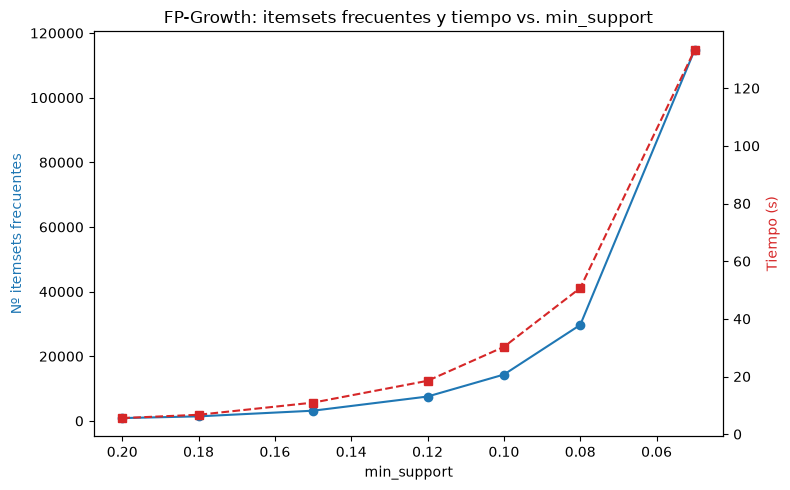

In [9]:
df_crecimiento_fpgrowth, ms_codo_fp = utils.barrido_min_support(df_matriz, valores_min_support, algoritmo=fpgrowth)
display(df_crecimiento_fpgrowth)
print(f"Mayor salto de complejidad en min_support={ms_codo_fp}")

graficar_barrido(df_crecimiento_fpgrowth, 'FP-Growth: itemsets frecuentes y tiempo vs. min_support')

Los resultados son idénticos a los de Apriori en número de itemsets, y a partir de 0,10 los tiempos vuelven a aumentar de forma muy notable. Por tanto, el rango a valorar sigue siendo entre 0,15 y 0,10, ya que fuera de él o bien obtenemos muy pocos itemsets, o bien demasiados, que no aportan valor y disparan los tiempos.

Siguiendo el mismo criterio que con Apriori, elegimos 0,15, ya que ofrece el mejor equilibrio entre el número de itemsets obtenidos y el tiempo de ejecución.

In [10]:
start = time.time()
frequent_itemsets_fpgrowth = fpgrowth(df_matriz, min_support=0.15, use_colnames=True, max_len=4)
tiempo_fpgrowth = time.time() - start

print(f"Itemsets frecuentes de FP-Growth: {len(frequent_itemsets_fpgrowth)}")
print(f"Tiempo de ejecución: {tiempo_fpgrowth:.2f} segundos")

Itemsets frecuentes de FP-Growth: 3165
Tiempo de ejecución: 8.34 segundos


**Verificación de equivalencia entre algoritmos**

Ahora que tenemos los dos algoritmos probados con varios valores y elegidos los parámetros definitivos, vamos a validar que producen los mismos itemsets y reglas bajo las mismas condiciones. Si los resultados no coincidieran, esto sería un indicio de error de implementación que requeriría revisión antes de continuar.

In [11]:
reglas_fpgrowth = association_rules(frequent_itemsets_fpgrowth, metric="confidence",min_threshold=0.6)

print(f"Itemsets — Apriori: {len(itemsets_frecuentes)} | FP-Growth: {len(frequent_itemsets_fpgrowth)}")
print(f"Reglas — Apriori: {len(reglas_asociacion)} | FP-Growth: {len(reglas_fpgrowth)}")

Itemsets — Apriori: 3165 | FP-Growth: 3165
Reglas — Apriori: 10178 | FP-Growth: 10178


Apriori y FP-Growth ofrecen exactamente los mismos resultados (3.165 itemsets y 10.178 reglas), por lo que cualquiera de los dos sería válido. Queda por comprobar cuál de ellos es más eficiente.

### 3.5 Comparativa de rendimiento: Apriori vs. FP-Growth

Como hemos comprobado, Apriori y FP-Growth generan exactamente los mismos itemsets y reglas con la misma configuración, por lo que queda por determinar cuál de ellos es más eficiente en tiempo de ejecución.

Para ello, volvemos a ejecutar Apriori con los mismos hiperparámetros y medimos su tiempo, comparándolo con el de FP-Growth obtenido en la sección anterior, para ver cuál es más rápido y en qué proporción.

In [12]:
start = time.time()
frequent_itemsets_apriori_tiempos = apriori(df_matriz, min_support=0.15, use_colnames=True, max_len=4, low_memory=True)
tiempo_apriori = time.time() - start

print(f"Tiempo Apriori:   {tiempo_apriori:.2f}s")
print(f"Tiempo FP-Growth: {tiempo_fpgrowth:.2f}s")
print(f"FP-Growth es {tiempo_apriori/tiempo_fpgrowth:.1f}x más rápido" if tiempo_fpgrowth < tiempo_apriori else f"Apriori es {tiempo_fpgrowth/tiempo_apriori:.1f}x más rápido")

Tiempo Apriori:   4.06s
Tiempo FP-Growth: 8.34s
Apriori es 2.1x más rápido


### 3.6 Tercer algoritmo: Eclat

El tercer algoritmo es **Eclat** (*Equivalence Class Clustering and Bottom-up Lattice Traversal*), que también utilizamos en el pipeline de soft skills. Su principal diferencia respecto a los anteriores es que no recorre el dataset fila a fila, sino que utiliza una representación vertical en la que cada ítem mantiene la lista de identificadores de las transacciones en las que aparece (*tidset*). A partir de estas listas, calcula el soporte de cada itemset mediante la **intersección** de los *tidsets* de sus componentes. En teoría, esta es una operación muy eficiente, lo que hace de Eclat un algoritmo atractivo por su coste computacional.

Como Eclat no está implementado en `mlxtend`, recurrimos a `pyECLAT`, la alternativa más extendida en Python. A diferencia de los dos algoritmos anteriores, `pyECLAT` espera el dataset en formato de **lista de transacciones**, donde cada fila contiene los nombres de los ítems presentes.

**¿Por qué se trabaja con una muestra de 10.000 filas y no con el dataset completo?** En las pruebas realizadas sobre el dataset completo con `max_combination=4` (el mismo alcance usado en Apriori y FP-Growth), la ejecución no llegaba a completarse en un tiempo razonable. Por ello, al igual que en el pipeline de soft skills, aplicamos el algoritmo sobre una muestra reducida y con un alcance menor (`max_combination=2`). Esto permite obtener una referencia orientativa de su rendimiento, aunque no estrictamente comparable con la de Apriori y FP-Growth, que se ejecutan sobre el dataset completo y con itemsets de hasta 4 ítems.

Hay que tener en cuenta que `pyECLAT` asume que el dataframe de entrada tiene un índice contiguo que empieza en 0. Al tomar una muestra, se conservan los índices originales, que no son contiguos, lo que provoca un fallo al construir la tabla binaria. Por ello, es necesario aplicar `.reset_index(drop=True)` sobre la muestra.

Con los resultados obtenidos, compararemos su rendimiento con el de los algoritmos anteriores.

**Transformación a formato de lista de transacciones**

Como `pyECLAT` no acepta la matriz binaria `df_matriz` como entrada, es necesario transformarla a una **lista de los nombres de los ítems presentes**, sin los ítems ausentes, algo que ya aprendimos del otro pipeline.

La función `matriz_a_transacciones` lo que hace es recorrer cada fila de `df_matriz` y, usando el propio booleano de cada columna como máscara (`row.index[row]`), de ellas extrae únicamente los nombres de las columnas activas (`True`) y descarta el resto.

In [13]:
def matriz_a_transacciones(df_bin):
    return df_bin.apply(lambda row: row.index[row].tolist(), axis=1)

transacciones = matriz_a_transacciones(df_matriz)
df_transacciones = pd.DataFrame(transacciones.tolist())

print(f"Forma del dataset de transacciones: {df_transacciones.shape}")
display(df_transacciones.head(3))

Forma del dataset de transacciones: (35434, 183)


,0,1,2,3,4,5,6,7,8,9,...,173,174,175,176,177,178,179,180,181,182
0,LanguageHaveWorkedWith_SQL,LanguageHaveWorkedWith_Bash/Shell (all shells),LanguageHaveWorkedWith_Dart,DatabaseHaveWorkedWith_PostgreSQL,DatabaseHaveWorkedWith_Cloud Firestore,PlatformHaveWorkedWith_Amazon Web Services (AWS),PlatformHaveWorkedWith_Google Cloud,PlatformHaveWorkedWith_Cloudflare,PlatformHaveWorkedWith_Gradle,DevEnvsHaveWorkedWith_Visual Studio Code,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,LanguageHaveWorkedWith_Java,DatabaseHaveWorkedWith_MongoDB,DatabaseHaveWorkedWith_Dynamodb,PlatformHaveWorkedWith_Docker,PlatformHaveWorkedWith_Amazon Web Services (AWS),PlatformHaveWorkedWith_Kubernetes,PlatformHaveWorkedWith_Homebrew,PlatformHaveWorkedWith_Terraform,PlatformHaveWorkedWith_Maven (build tool),WebframeHaveWorkedWith_Spring Boot,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,RemoteWork_is_missing,OrgSize_is_missing,LanguageHaveWorkedWith_JavaScript,LanguageHaveWorkedWith_HTML/CSS,LanguageHaveWorkedWith_TypeScript,LanguageHaveWorkedWith_Dart,DatabaseHaveWorkedWith_PostgreSQL,DatabaseHaveWorkedWith_MySQL,DatabaseHaveWorkedWith_MongoDB,PlatformHaveWorkedWith_npm,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Como cada candidato tiene un número distinto de ítems activos (por ejemplo, quien trabaja con pocas tecnologías o dejó varias preguntas sin responder tendrá menos ítems marcados que alguien con un perfil completo), al convertir la lista de listas en un dataframe, pandas iguala todas las filas a la longitud de la más larga y rellena los huecos sobrantes con valores nulos. Por lo tanto, el número de columnas (183) corresponde al **máximo de ítems activos de un único candidato** en todo el dataset, y no al número de columnas de `df_matriz` (263).

Por otro lado, en las siguientes celdas comparamos dos posibles valores de `min_support` (0,15 y 0,10), de la misma forma que se hizo con Apriori y FP-Growth, para quedarnos con el más adecuado y realizar después la comparación final entre los tres algoritmos.


In [14]:
muestra = df_transacciones.sample(n=10000, random_state=42).reset_index(drop=True)
itemsets_eclat, tiempo_eclat_muestra = utils.probar_eclat(muestra, min_support=0.15)

100%|██████████| 263/263 [00:00<00:00, 2206.41it/s]


Combination 1 by 1


80it [00:03, 20.03it/s]


Combination 2 by 2


3160it [01:32, 34.17it/s]

Tiempo ECLAT (min_support=0.15): 247.53s — 669 itemsets


In [15]:
itemsets_eclat_010, tiempo_eclat_010 = utils.probar_eclat(muestra, min_support=0.10)
print(f"Comparación: 0.15 → {tiempo_eclat_muestra:.2f}s ({len(itemsets_eclat)} itemsets) | "
      f"0.10 → {tiempo_eclat_010:.2f}s ({len(itemsets_eclat_010) if itemsets_eclat_010 is not None else 0} itemsets)")

100%|██████████| 263/263 [00:00<00:00, 2185.01it/s]


Combination 1 by 1


130it [00:06, 19.94it/s]


Combination 2 by 2


8385it [44:00,  3.18it/s] 

Tiempo ECLAT (min_support=0.1): 2798.83s — 1496 itemsets
Comparación: 0.15 → 247.53s (669 itemsets) | 0.10 → 2798.83s (1496 itemsets)


La comparativa muestra que, al bajar a 0,10, el tiempo de Eclat se multiplica por 11,3 (de 247,53s a 2.798,83s), lo que lo hace inviable para nuestros intereses, sobre todo frente a los otros dos algoritmos. Por ello, elegimos también 0,15, equiparando así este valor con el de Apriori y FP-Growth.

### 3.6.1 Resumen comparativo de los tres algoritmos

| Algoritmo | Filas procesadas | Alcance combinación | Tiempo | Itemsets frecuentes |
|---|---|---|---|---|
| Apriori (`low_memory=True`) | 35.434 (completo) | hasta 4 | 4,06s | 3.165 |
| FP-Growth | 35.434 (completo) | hasta 4 | 8,34s | 3.165 |
| Eclat (`pyECLAT`) | 10.000 (muestra) | hasta 2 | 247,53s | 669 |

*Todos los algoritmos se ejecutan con `min_support=0.15`.*

**Conclusiones del bloque de comparación de algoritmos:**

1. **Apriori y FP-Growth son equivalentes en resultado** (3.165 itemsets y 10.178 reglas idénticas bajo los mismos umbrales), lo que confirma empíricamente que ambos algoritmos resuelven el mismo problema y solo difieren en la estrategia de recorrido del espacio de búsqueda.

2. **Apriori resultó más rápido que FP-Growth** (4,06s frente a 8,34s, unas 2,1 veces), una diferencia de magnitud casi idéntica a la observada en el pipeline de soft skills (2,2 veces), lo que refuerza que no es un resultado casual de un dataset concreto.

3. **Eclat (vía `pyECLAT`) resultó sustancialmente más lento en la práctica**, incluso trabajando sobre una muestra y con un alcance menor, lo que es coherente con la brecha entre la eficiencia teórica de Eclat y el coste real de esta implementación en Python, sin vectorización.

4. **El barrido de `min_support` (Sección 3.2) confirma que 0,15 es un punto de equilibrio razonable**: bajar a 0,10 multiplica por 4,3-4,5 el número de reglas e itemsets en Apriori/FP-Growth, y en Eclat multiplica por 2,2 los itemsets y por 11,3 el tiempo de ejecución (de 247,53s a 2.798,83s). Cabe destacar que el barrido no revela un punto de inflexión (codo) genuino en ningún valor probado, ya que la tasa de crecimiento aumenta de forma continua en todo el rango, por lo que la elección de 0,15 no responde a un óptimo matemático, sino a un criterio de manejabilidad práctica, tal y como se razonó en la Sección 3.2.

5. **Los hiperparámetros empleados en los tres algoritmos se han fijado mediante pruebas manuales, no mediante una búsqueda sistemática de optimización.** En Apriori, `max_len=4` y `low_memory=True` se justificaron por la interpretabilidad de las reglas y el control de memoria, pero no se ha explorado si otros valores ofrecerían un mejor equilibrio entre cobertura y coste computacional. Lo mismo ocurre con `min_support`: aunque el barrido explora varios valores, la elección final de 0,15 responde a un criterio de manejabilidad práctica (condicionado también por la memoria disponible en la máquina), no a un proceso de optimización formal. Estas limitaciones se aplican también a FP-Growth (que comparte `min_support` y `max_len` con Apriori) y a Eclat (`max_combination` y el tamaño de la muestra, 10.000 candidatos, muy inferior al dataset completo). Una búsqueda sistemática de hiperparámetros para los tres algoritmos, idealmente en un entorno con mayor capacidad de memoria que permita explorar valores de `min_support` más bajos, queda como línea de trabajo futuro.

En conjunto, estos resultados justifican la elección de **Apriori** como algoritmo principal para el resto del proyecto, reservando FP-Growth como validación de equivalencia y Eclat como referencia comparativa de rendimiento.

### 3.7 Exportación de la "Base de Conocimiento"

Las reglas generadas por Apriori (`reglas_asociacion`) y su versión depurada tras el filtrado de nulos y redundancia (`reglas_limpias`) se exportan a CSV para utilizarlas en las fases posteriores del proyecto, donde se contrastarán con las reglas expertas de la misma forma que en el pipeline de soft skills.

Exportamos ambos conjuntos por transparencia: `reglas_asociacion` (10.178 reglas en bruto) en `reglas_apriori_hard.csv`, y `reglas_limpias` (10.107 reglas depuradas), que son las que se utilizarán a partir de ahora, en `reglas_limpias_hard.csv`.

En cuanto al formato, las columnas `antecedents` y `consequents` de `mlxtend` son objetos `frozenset`, que no tienen una representación legible ni reconstruible en un fichero CSV plano. Por ello, antes de exportarlas las convertimos en cadenas de texto con los ítems ordenados alfabéticamente y separados por `" | "`, de modo que el fichero sea legible y permita realizar comparaciones posteriores. Se descartó la coma como separador porque al menos una categoría de `Employment` contiene comas en su propio nombre (*"Independent contractor, freelancer, or self-employed"*), lo que generaría ambigüedad.

In [16]:
def exportar_reglas(df_reglas, path):
    df_export = df_reglas.copy()
    df_export['antecedents'] = df_export['antecedents'].apply(lambda x: ' | '.join(sorted(x)))
    df_export['consequents'] = df_export['consequents'].apply(lambda x: ' | '.join(sorted(x)))
    df_export.to_csv(path, index=False)
    print(f"Guardado en {path} — {len(df_export)} reglas")

exportar_reglas(reglas_asociacion, config.REGLAS_APRIORI_PATH)
exportar_reglas(reglas_limpias, config.REGLAS_LIMPIAS_PATH)

Guardado en /home/miguel-angel/Escritorio/TFM/data/processed/hard_skills/reglas_apriori_hard.csv — 10178 reglas
Guardado en /home/miguel-angel/Escritorio/TFM/data/processed/hard_skills/reglas_limpias_hard.csv — 10107 reglas


### 3.8 Resumen final de la extracción de reglas

Tras la minería de reglas con Apriori (`min_support=0.15`, `max_len=4`, `min_confidence=0.6`), el proceso de filtrado y la exportación final, se obtienen los siguientes resultados:

| Archivo | Nº de reglas |
|---|---|
| `reglas_apriori_hard.csv` (sin filtrar) | 10.178 |
| `reglas_limpias_hard.csv` (sin nulos ni redundancia) | 10.107 |

Sobre las 10.107 reglas limpias, las métricas se distribuyen así: soporte medio de 0,186 (mínimo 0,15 por construcción, máximo 0,639), confianza media de 0,740 y lift medio de 1,559 (máximo 2,900).

Los ítems más frecuentes en estas reglas son coherentes con lo visto en la Libreta 1 (EDA): `CommPlatformHaveWorkedWith_GitHub (public projects, not private repos)`, `CommPlatformHaveWorkedWith_Stack Overflow`, `Employment_Employed`, `LanguageHaveWorkedWith_JavaScript` e `ICorPM_Individual contributor` encabezan el ranking, ya que corresponden a los rasgos más extendidos entre los candidatos y, por tanto, participan en un mayor número de combinaciones frecuentes.